## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts?
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Sid Luthra

**Date:** 10/12/26

In [1]:
#Q1:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler

def createData(noise, N=50):
    np.random.seed(100)

    X1 = np.array([
        np.random.normal(1, noise, N),
        np.random.normal(1, noise, N)
    ])
    X2 = np.array([
        np.random.normal(3, noise, N),
        np.random.normal(2, noise, N)
    ])
    X3 = np.array([
        np.random.normal(5, noise, N),
        np.random.normal(3, noise, N)
    ])

    gdf1 = pd.DataFrame({'x1': X1[0], 'x2': X1[1], 'group': 'a'})
    gdf2 = pd.DataFrame({'x1': X2[0], 'x2': X2[1], 'group': 'b'})
    gdf3 = pd.DataFrame({'x1': X3[0], 'x2': X3[1], 'group': 'c'})

    return pd.concat([gdf1, gdf2, gdf3], axis=0)

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

datasets = {
    0.125: df0_125,
    0.25: df0_25,
    0.5: df0_5,
    1.0: df1_0,
    2.0: df2_0
}


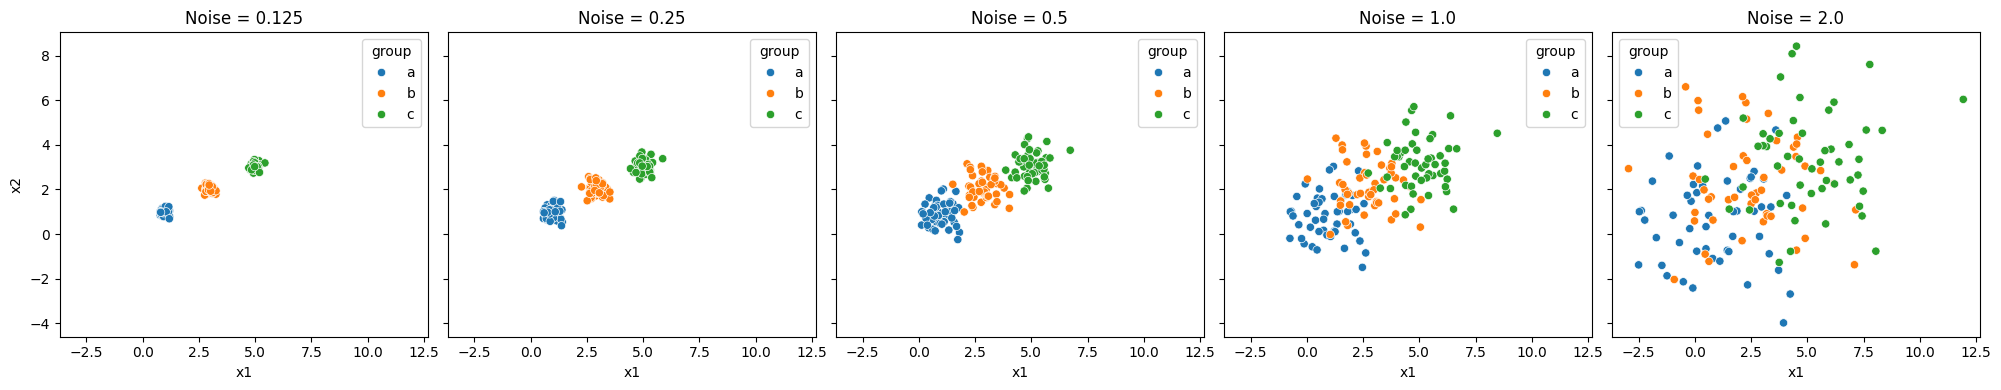

In [2]:
#Q1.2:
fig, axes = plt.subplots(1, 5, figsize=(20, 4),
                         sharex=True, sharey=True)

for ax, (noise, data) in zip(axes, datasets.items()):
    sns.scatterplot(
        data=data, x='x1', y='x2',
        hue='group', ax=ax
    )
    ax.set_title(f"Noise = {noise}")

plt.tight_layout()
plt.show()

At noise levels of 0.125 and 0.25, the three groups form tight,
clearly separated clusters. At 0.5, the groups spread out and begin
to overlap. At 1.0 and 2.0, the overlap becomes substantial, making
the original groups harder to distinguish visually.

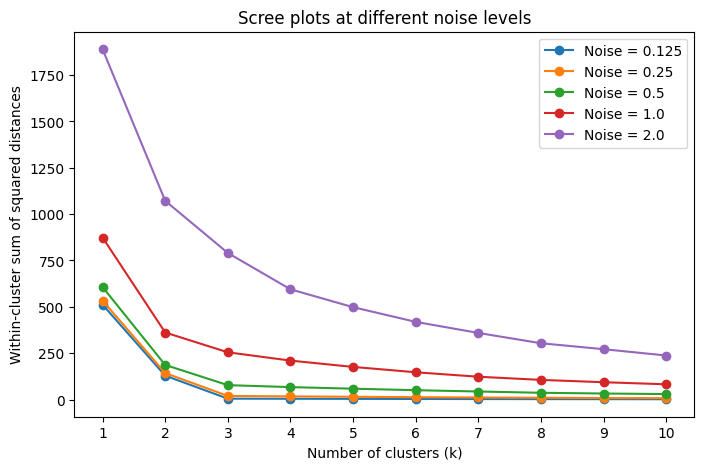

In [3]:
#Q1.3:
ks = range(1, 11)

plt.figure(figsize=(8, 5))

for noise, data in datasets.items():
    inertias = []

    for k in ks:
        model = KMeans(
            n_clusters=k, random_state=100, n_init=10
        )
        model.fit(data[['x1', 'x2']])
        inertias.append(model.inertia_)

    plt.plot(ks, inertias, marker='o', label=f"Noise = {noise}")

plt.xlabel("Number of clusters (k)")
plt.ylabel("Within-cluster sum of squared distances")
plt.title("Scree plots at different noise levels")
plt.xticks(list(ks))
plt.legend()
plt.show()

Q1.3:
At low noise, the curves go down steeply until around k = 3 and then they flatten, which makes three clusters a clear choice. When noise increases, the within-cluster sum of squared distances increases. The higher-noise curves decline more slowly, so selecting one k confidently becomes much harder.

Q1.4:
The elbow marks where adding more clusters starts producing smaller improvements. With three separated groups, increasing k from one to three allows each group to have its own center, greatly reducing squared distances. Beyond three, additional centers mostly divide existing groups, so the improvement is small.
With more noise, the groups overlap and extra centers continue to reduce distances, making the elbow less obvious.

In [4]:
df = pd.read_csv("SIPRI Military Expenditure Database.csv")

df = df[df['Year'] == 2020].dropna().copy()

variables = [
    'Spending (2020 USD)',
    'Spending per Capita',
    'Percent of Government Spending',
    'Percent of GDP'
]

print("Number of countries:", len(df))
print(df[variables].dtypes)

Number of countries: 148
Spending (2020 USD)               float64
Spending per Capita               float64
Percent of Government Spending    float64
Percent of GDP                    float64
dtype: object


Q2.1:
After filtering to 2020 and dropping rows with missing values, 148 countries remain.

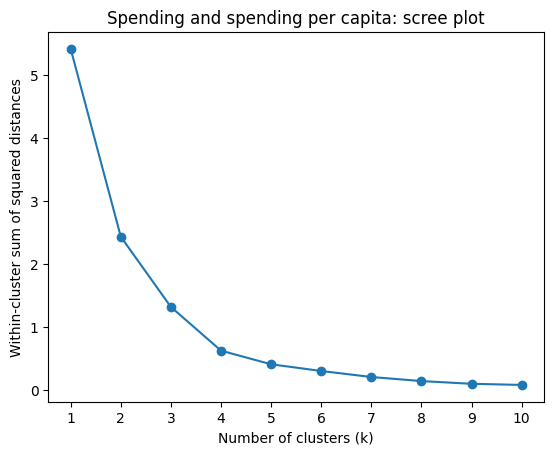

In [5]:
#Q2.2:
spending_cols = [
    'Spending (2020 USD)',
    'Spending per Capita'
]

X_spending = MinMaxScaler().fit_transform(df[spending_cols])

inertias = []

for k in ks:
    model = KMeans(n_clusters=k, random_state=100, n_init=10)
    model.fit(X_spending)
    inertias.append(model.inertia_)

plt.plot(ks, inertias, marker='o')
plt.xlabel("Number of clusters (k)")
plt.ylabel("Within-cluster sum of squared distances")
plt.title("Spending and spending per capita: scree plot")
plt.xticks(list(ks))
plt.show()

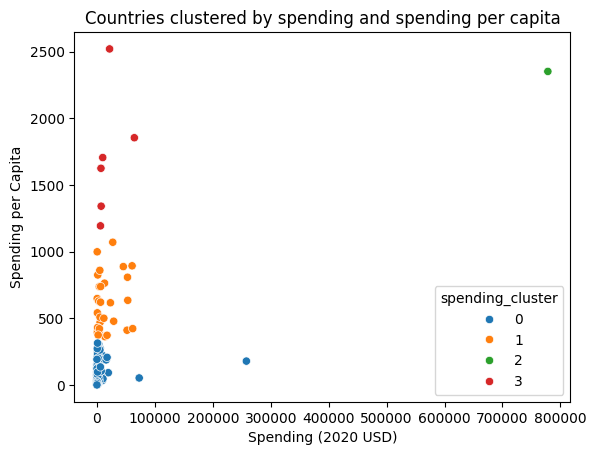

Spending (2020 USD)                               \
                               count           mean           std   
spending_cluster                                                    
0                              111.0    4859.185065  25405.739131   
1                               30.0   17077.591354  20583.053357   
2                                1.0  778397.200000           NaN   
3                                6.0   19443.362047  22861.507114   

                                                                              \
                            min            25%            50%            75%   
spending_cluster                                                               
0                      8.622460     130.010211     382.464677    2297.032353   
1                    405.790494    2294.039665    5857.060906   26296.001003   
2                 778397.200000  778397.200000  778397.200000  778397.200000   
3                   6095.708713    7023.251766    8624.225729   18857.070183   

                                Spending per Capita                           \
                            max               count         mean         std   
spending_cluster                                                               
0                 257973.429834               111.0    80.061470   83.501824   
1                  61712.537169                30.0   607.478618  206.928757   
2                 778397.200000                 1.0  2351.631858         NaN   
3                  64558.400000                 6.0  1706.721916  466.375705   

                                                                      \
                          min          25%          50%          75%   
spending_cluster                                                       
0                    0.580129    14.880549    47.056944   125.387558   
1                  362.467076   422.208252   579.004604   757.328513   
2                 2351.631858  2351.631858  2351.631858  2351.631858   
3                 1193.598730  1412.083201  1665.447478  1817.219993   

                               
                          max  
spending_cluster               
0                  314.201312  
1                 1070.623322  
2                 2351.631858  
3                 2520.398541

,Country,spending_cluster,Spending (2020 USD),Spending per Capita
5540,United States of America,2,778397.2,2351.631858


In [6]:
df['spending_cluster'] = KMeans(
    n_clusters=4, random_state=100, n_init=10
).fit_predict(X_spending)

sns.scatterplot(
    data=df,
    x='Spending (2020 USD)',
    y='Spending per Capita',
    hue='spending_cluster',
    palette='tab10'
)
plt.title("Countries clustered by spending and spending per capita")
plt.show()

display(df.groupby('spending_cluster')[spending_cols].describe())

display(
    df.loc[
        df['Country'] == 'United States of America',
        ['Country', 'spending_cluster'] + spending_cols
    ]
)

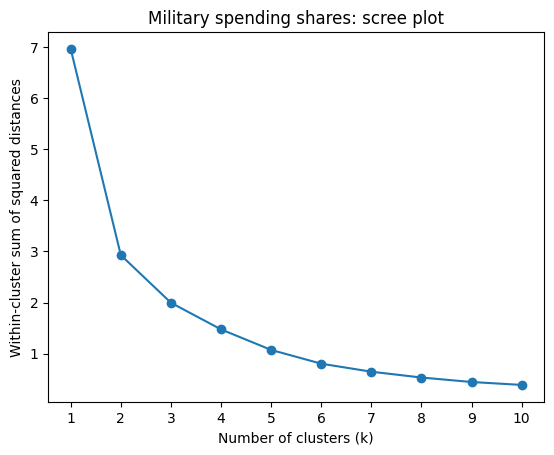

In [7]:
#Q2.3:
percent_cols = [
    'Percent of Government Spending',
    'Percent of GDP'
]

X_percent = MinMaxScaler().fit_transform(df[percent_cols])

inertias = []

for k in ks:
    model = KMeans(n_clusters=k, random_state=100, n_init=10)
    model.fit(X_percent)
    inertias.append(model.inertia_)

plt.plot(ks, inertias, marker='o')
plt.xlabel("Number of clusters (k)")
plt.ylabel("Within-cluster sum of squared distances")
plt.title("Military spending shares: scree plot")
plt.xticks(list(ks))
plt.show()

I selected k = 2 because the largest decrease occurs between one and two clusters, after which the curve declines more gradually.

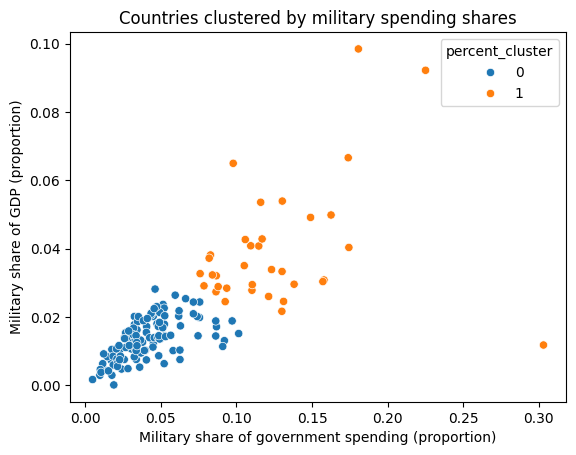

Percent of Government Spending                                \
                                         count      mean       std       min   
percent_cluster                                                                
0                                        113.0  0.041394  0.020681  0.004896   
1                                         35.0  0.126456  0.046209  0.076005   

                                                        Percent of GDP  \
                      25%       50%       75%       max          count   
percent_cluster                                                          
0                0.026783  0.038486  0.051496  0.101501          113.0   
1                0.093093  0.116052  0.143584  0.303027           35.0   

                                                                             \
                     mean       std       min       25%       50%       75%   
percent_cluster                                                               
0                0.013481  0.005966  0.000054  0.009147  0.013631  0.017830   
1                0.039433  0.018179  0.011742  0.028962  0.033281  0.042722   

                           
                      max  
percent_cluster            
0                0.028132  
1                0.098470

,Country,percent_cluster,Percent of Government Spending,Percent of GDP
5540,United States of America,1,0.081976,0.037179


In [8]:
df['percent_cluster'] = KMeans(
    n_clusters=2, random_state=100, n_init=10
).fit_predict(X_percent)

sns.scatterplot(
    data=df,
    x='Percent of Government Spending',
    y='Percent of GDP',
    hue='percent_cluster',
    palette='tab10'
)
plt.xlabel("Military share of government spending (proportion)")
plt.ylabel("Military share of GDP (proportion)")
plt.title("Countries clustered by military spending shares")
plt.show()

display(df.groupby('percent_cluster')[percent_cols].describe())

display(
    df.loc[
        df['Country'] == 'United States of America',
        ['Country', 'percent_cluster'] + percent_cols
    ]
)

In [9]:
#Q2.4:
X_all = MinMaxScaler().fit_transform(df[variables])

df['all_cluster'] = KMeans(
    n_clusters=3, random_state=100, n_init=10
).fit_predict(X_all)

display(df.groupby('all_cluster')[variables].mean())
display(df.groupby('all_cluster').size().rename('Country count'))

display(
    df.loc[
        df['Country'] == 'United States of America',
        ['Country', 'spending_cluster', 'percent_cluster', 'all_cluster']
    ]
)

us_cluster = df.loc[
    df['Country'] == 'United States of America', 'all_cluster'
].iloc[0]

display(df.loc[df['all_cluster'] == us_cluster, ['Country']])

,Spending (2020 USD),Spending per Capita,Percent of Government Spending,Percent of GDP
all_cluster,,,,
0,7086.472777,196.926833,0.040350,0.013419
1,147964.582042,1875.150751,0.135351,0.062634
2,8786.086602,212.689100,0.122985,0.033492


,Country count
all_cluster,
0,111
1,6
2,31


,Country,spending_cluster,percent_cluster,all_cluster
5540,United States of America,2,1,1


,Country
2582,Israel
2922,Kuwait
4044,Oman
4486,Saudi Arabia
4656,Singapore
5540,United States of America


Q2.5:

K-means determined some useful differences between countries with high military spending amounts and countries that devote large shares of their budgets or economies to the military. The United States stands out most strongly when total spending is included, while other countries stand out more by their spending shares. These patterns help summarize the data, although the groups depend on the variables, normalization, and number of clusters chosen.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** ChatGPT Model: Astra 6 Max

### *Prompts used

1. 1. "Use the notebook and the rubric to give me any revisions that I might need to make based on where I might be lacking on the rubric" (attached: Phase 1 notebook PDF, the SIPRI CSV, and a screenshot of the Phase 2 rubric)


### *AI-proposed changes


**Q1**
1. **Retain the existing shared-axis scatterplots and combined scree plot — Accept.** These already make the five noise levels comparable. They are retained, not claimed as new improvements.
2. **Add a numerical check of the elbow — Accept.** Compare the reduction in within-cluster sum of squares (WCSS) from k = 2 to 3 with the reduction from k = 3 to 4.
3. **Clarify the high-noise explanation — Modify.** Describe the elbow as less distinct; do not claim that every high-noise curve has a smaller absolute slope. Absolute WCSS also increases with noise.
4. **Include the complete Q1 solution in Phase 2 — Accept.** The earlier AI-assisted draft visible in the PDF focused on Q2 and did not include a final Q1 section.

**Q2**
1. **Answer the cleaning question explicitly — Accept.** Check numeric types, missing values, duplicate countries, and the units of the percentage variables.
2. **Add cluster-choice explanations and interpretations — Accept.** Explain the spending groups, the U.S. location, and the differences between variable combinations.
3. **Improve the spending scatterplot — Modify.** Use logarithmic axes for display, but fit K-means on the min-max-normalized original variables.
4. **Add the four-variable scree plot — Accept.** Support k = 3 with the plotted reductions and describe it as a reasonable choice rather than a unique optimum.
5. **Include a reproducible seed-stability check — Modify.** The earlier draft mentioned ARI = 1.0 without a visible supporting check in the PDF. Include the actual check below and restrict its conclusion to repeatability across the tested seeds.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| Keep Q1’s shared-axis scatterplots and combined scree plot | Accept | The shared axes allow a consistent comparison across noise levels. The plots show increasing overlap and a less distinct elbow as noise rises. |
| Add numerical evidence for Q1’s elbow | Accept | At noise 0.125, WCSS drops 123.974 from k = 2 to k = 3, but only 0.580 from k = 3 to k = 4. At noise 2.0, the corresponding drops are 281.333 and 195.930, making the elbow less decisive. |
| Revise Q1’s explanation of high-noise curves | Modify | The earlier wording suggested that higher-noise curves always decline more slowly. The plotted values show that absolute WCSS rises with noise; the supported conclusion is that the elbow becomes less clear. |
| Include a complete Q1 solution in Phase 2 | Accept | The earlier Phase 2 draft addressed Q2 but omitted Q1. The revised cells include Q1’s plots, numerical check, and answers to parts 2–4. |
| Audit Q2’s data cleaning | Accept | The data check found 173 rows for 2020 and 148 after dropping missing values. The four clustering variables are numeric, with no remaining missing values or duplicate countries. |
| Explain Q2.2’s cluster choice and interpret the groups | Accept | The scree plot supports k = 4 as a reasonable choice. The group summary shows 111, 30, 1, and 6 countries; the United States is the one-country cluster. |
| Make Q2.2’s scatterplot readable | Modify | Logarithmic plot axes spread out the crowded points. The clustering still uses min-max-normalized original values, so changing the display does not change cluster membership. |
| Interpret Q2.3 and compare it with Q2.2 | Accept | The scree plot supports k = 2. The group summaries contain 113 and 35 countries, and the cross-tabulation confirms that grouping by spending shares differs from grouping by spending amounts. |
| Add Q2.4’s scree plot and comparison | Accept | The scree plot makes k = 3 a reasonable, though not unique, choice. The summaries and cross-tabulations show that the United States joins five other countries when all four variables are used. |
| Verify the earlier claim about cluster stability | Modify | A reproducible check compares each Q2 result with fits using seeds 0–4. All comparisons produced an adjusted Rand index of 1.0, showing identical memberships across those seeds. This check does not prove that the chosen k is optimal. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import adjusted_rand_score

p2_ks = range(1, 11)

def p2_fit(X, k, seed=100):
    return KMeans(
        n_clusters=k, random_state=seed, n_init=10
    ).fit(X)

def p2_scree(X, title):
    values = [p2_fit(X, k).inertia_ for k in p2_ks]
    plt.figure(figsize=(7, 4))
    plt.plot(list(p2_ks), values, marker="o")
    plt.xticks(list(p2_ks))
    plt.xlabel("Number of clusters (k)")
    plt.ylabel("Within-cluster sum of squares")
    plt.title(title)
    plt.tight_layout()
    plt.show()
    return values

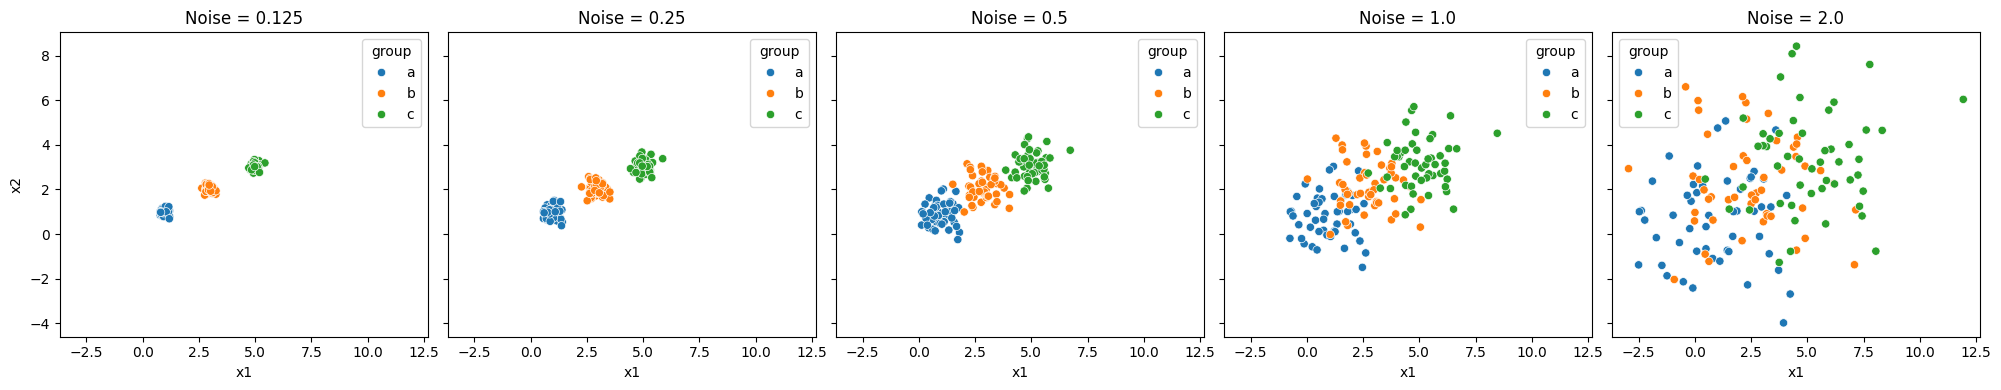

In [18]:
# Q1.1 and Q1.2: recreate the five datasets.
def p2_create_data(noise, N=50):
    rng = np.random.RandomState(100)
    groups = []

    for label, (cx, cy) in zip(
        ["a", "b", "c"], [(1, 1), (3, 2), (5, 3)]
    ):
        groups.append(pd.DataFrame({
            "x1": rng.normal(cx, noise, N),
            "x2": rng.normal(cy, noise, N),
            "group": label
        }))

    return pd.concat(groups, ignore_index=True)

p2_datasets = {
    noise: p2_create_data(noise)
    for noise in [0.125, 0.25, 0.5, 1.0, 2.0]
}

fig, axes = plt.subplots(
    1, 5, figsize=(20, 4), sharex=True, sharey=True
)

for ax, (noise, data) in zip(axes, p2_datasets.items()):
    sns.scatterplot(
        data=data, x="x1", y="x2", hue="group", ax=ax
    )
    ax.set_title(f"Noise = {noise}")

plt.tight_layout()
plt.show()

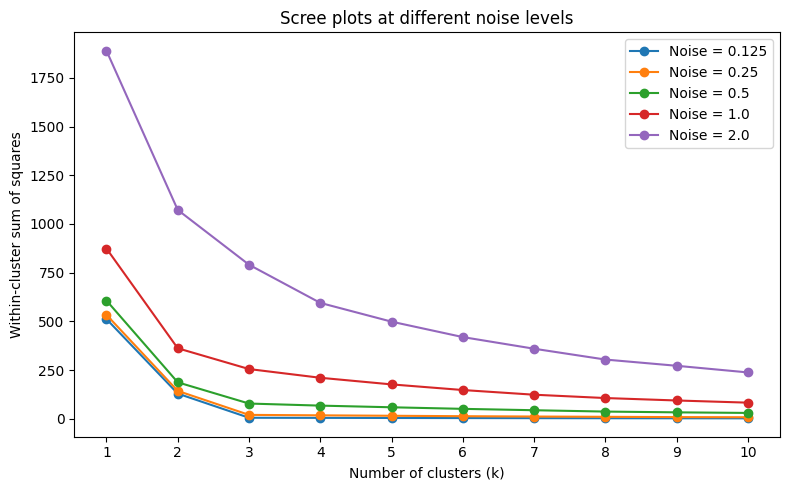

,Noise,WCSS at k=3,Reduction: k=2 to 3,Reduction: k=3 to 4
0,0.125,4.913,123.974,0.580
1,0.250,19.653,123.068,2.318
2,0.500,77.817,108.964,10.625
3,1.000,254.882,106.706,44.732
4,2.000,790.479,281.333,195.930


In [19]:
# Q1.3: compare all scree curves on the same axes.
p2_q1_inertias = {}
p2_q1_checks = []

plt.figure(figsize=(8, 5))

for noise, data in p2_datasets.items():
    X = data[["x1", "x2"]]
    values = [p2_fit(X, k).inertia_ for k in p2_ks]
    p2_q1_inertias[noise] = values

    plt.plot(
        list(p2_ks), values, marker="o", label=f"Noise = {noise}"
    )

    p2_q1_checks.append({
        "Noise": noise,
        "WCSS at k=3": values[2],
        "Reduction: k=2 to 3": values[1] - values[2],
        "Reduction: k=3 to 4": values[2] - values[3]
    })

plt.xticks(list(p2_ks))
plt.xlabel("Number of clusters (k)")
plt.ylabel("Within-cluster sum of squares")
plt.title("Scree plots at different noise levels")
plt.legend()
plt.tight_layout()
plt.show()

display(pd.DataFrame(p2_q1_checks).round(3))

Q1.2: Visual distinctness
At noise levels 0.125 and 0.25, the three groups are tight and clearly separated. At 0.5, the groups spread out and begin to overlap. At 1.0 and 2.0, substantial overlap makes the original groups harder to distinguish. The shared axes keep the visual comparison consistent.

Q1.3: Noise and the scree plots
At low noise, the curves drop substantially until about k = 3 and then flatten, making three clusters a clear choice. As noise increases, WCSS increases and the elbow becomes less distinct.
For example, at noise 0.125, the reduction from k = 2 to 3 is about 123.974, compared with only 0.580 from k = 3 to 4. At noise 2.0, those reductions are about 281.333 and 195.930. Adding a fourth center still provides a substantial improvement at high noise, so the elbow gives less decisive evidence for k = 3.

Q1.4: Intuition of the elbow
WCSS measures how far points are from their assigned cluster centers, using squared distances. With three well-separated groups, going from one center to three lets each group have its own center and greatly reduces WCSS. Beyond three, extra centers mainly split existing groups, giving smaller improvements. The elbow is the transition between those large and small improvements.
With overlapping groups, extra centers can continue reducing WCSS substantially. Although the simulation has three generating groups, the scree plot alone may not clearly recover that number. A lower WCSS by itself does not establish a better or more meaningful choice of k.

In [20]:
# Q2.1: accept either the assignment's data folder or a Colab upload.
p2_path = Path("data/SIPRI Military Expenditure Database.csv")
if not p2_path.exists():
    p2_path = Path("SIPRI Military Expenditure Database.csv")

p2_raw = pd.read_csv(p2_path)
p2_2020 = p2_raw.loc[p2_raw["Year"] == 2020]
p2_df = p2_2020.dropna().copy()

p2_variables = [
    "Spending (2020 USD)",
    "Spending per Capita",
    "Percent of Government Spending",
    "Percent of GDP"
]
p2_spending_cols = p2_variables[:2]
p2_percent_cols = p2_variables[2:]

print("2020 rows before dropping missing values:", len(p2_2020))
print("Countries remaining:", len(p2_df))
print("Rows removed:", len(p2_2020) - len(p2_df))
print("Duplicate countries:", p2_df["Country"].duplicated().sum())
print("\nNumeric variable types:")
print(p2_df[p2_variables].dtypes)
print("\nMissing values:")
print(p2_df[p2_variables].isna().sum())
display(p2_df[p2_variables].agg(["min", "max"]))

2020 rows before dropping missing values: 173
Countries remaining: 148
Rows removed: 25
Duplicate countries: 0

Numeric variable types:
Spending (2020 USD)               float64
Spending per Capita               float64
Percent of Government Spending    float64
Percent of GDP                    float64
dtype: object

Missing values:
Spending (2020 USD)               0
Spending per Capita               0
Percent of Government Spending    0
Percent of GDP                    0
dtype: int64


,Spending (2020 USD),Spending per Capita,Percent of Government Spending,Percent of GDP
min,8.62246,0.580129,0.004896,0.000054
max,778397.20000,2520.398541,0.303027,0.098470


Q2.1: Cleaning

Filtering to 2020 gives 173 rows. Dropping rows with missing values leaves 148 countries, so 25 rows are excluded. The four clustering variables are already numeric, no missing values remain, and there are no duplicate countries. No additional type conversion or duplicate removal is needed for these variables.
The columns labeled "Percent" contain proportions: for example, 0.037179 represents approximately 3.72%, not 0.037179%. They can remain as proportions for clustering. Min-max normalization is still needed to put the different variables on comparable ranges.
Only the four requested numeric variables are used as clustering features; the index, year, and country name are excluded. Removing countries with missing data limits the coverage of the conclusions.

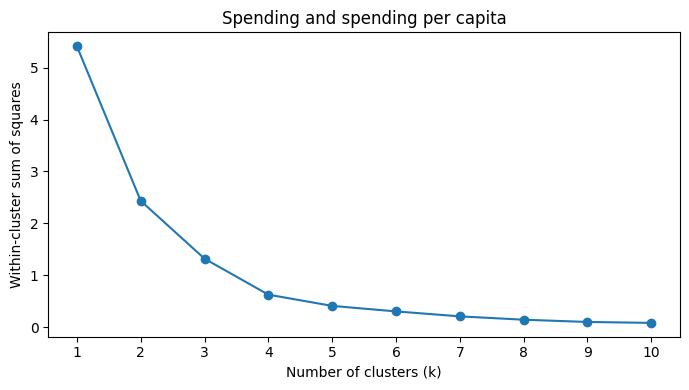

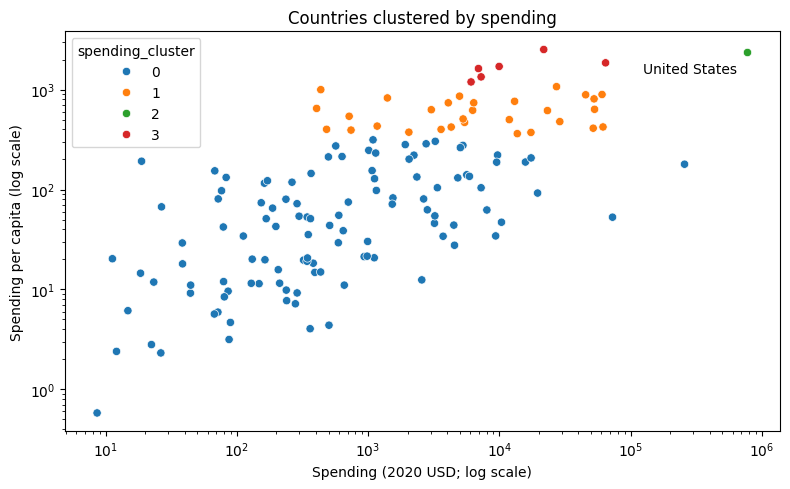

spending_cluster                    0          1           2          3
Spending (2020 USD) count     111.000     30.000       1.000      6.000
                    mean     4859.185  17077.591  778397.200  19443.362
                    std     25405.739  20583.053         NaN  22861.507
                    min         8.622    405.790  778397.200   6095.709
                    25%       130.010   2294.040  778397.200   7023.252
                    50%       382.465   5857.061  778397.200   8624.226
                    75%      2297.032  26296.001  778397.200  18857.070
                    max    257973.430  61712.537  778397.200  64558.400
Spending per Capita count     111.000     30.000       1.000      6.000
                    mean       80.061    607.479    2351.632   1706.722
                    std        83.502    206.929         NaN    466.376
                    min         0.580    362.467    2351.632   1193.599
                    25%        14.881    422.208    2351.632   1412.083
                    50%        47.057    579.005    2351.632   1665.447
                    75%       125.388    757.329    2351.632   1817.220
                    max       314.201   1070.623    2351.632   2520.399

,Country,spending_cluster,Spending (2020 USD),Spending per Capita
5540,United States of America,2,778397.2,2351.631858


In [21]:
# Q2.2: min-max normalize the two spending variables.
p2_X_spending = MinMaxScaler().fit_transform(
    p2_df[p2_spending_cols]
)
p2_spending_wcss = p2_scree(
    p2_X_spending, "Spending and spending per capita"
)

p2_df["spending_cluster"] = p2_fit(p2_X_spending, 4).labels_

fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(
    data=p2_df,
    x=p2_spending_cols[0],
    y=p2_spending_cols[1],
    hue="spending_cluster",
    palette="tab10",
    ax=ax
)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Spending (2020 USD; log scale)")
ax.set_ylabel("Spending per capita (log scale)")
ax.set_title("Countries clustered by spending")

p2_us = p2_df.loc[
    p2_df["Country"] == "United States of America"
].iloc[0]
ax.annotate(
    "United States",
    (p2_us[p2_spending_cols[0]], p2_us[p2_spending_cols[1]]),
    xytext=(-75, -15),
    textcoords="offset points"
)
plt.tight_layout()
plt.show()

display(
    p2_df.groupby("spending_cluster")[p2_spending_cols]
    .describe().T.round(3)
)
display(
    p2_df.loc[
        p2_df["Country"] == "United States of America",
        ["Country", "spending_cluster"] + p2_spending_cols
    ]
)

### Q2.2: Results

A reasonable elbow is k = 4: WCSS falls from approximately 5.411 at k = 1 to 0.629 at k = 4, with smaller improvements afterward. The elbow is a judgment rather than proof that four is the only valid choice.

With the fixed seed used here:
- Cluster 0 contains 111 countries, with average spending per capita of about 80.1. It includes China, showing that a country can have high total spending while belonging to a group with lower spending per person.
- Cluster 1 contains 30 countries, with average spending per capita of about 607.5.
- Cluster 2 contains only the United States, which has by far the largest total expenditure and spending per capita of about 2,351.6.
- Cluster 3 contains six countries, with average spending per capita of about 1,706.7.

The U.S. singleton explains the NaN standard deviation in its describe table: a sample standard deviation cannot be computed from one observation.

The plot uses logarithmic axes to make crowded points easier to see. K-means still uses the min-max-normalized original values. The plot's log scales do not change the fitted clusters. Outliers remain influential under min-max normalization, and the cluster numbers themselves are arbitrary labels.

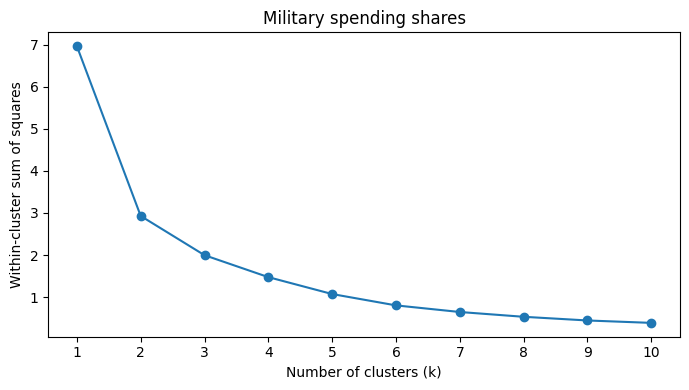

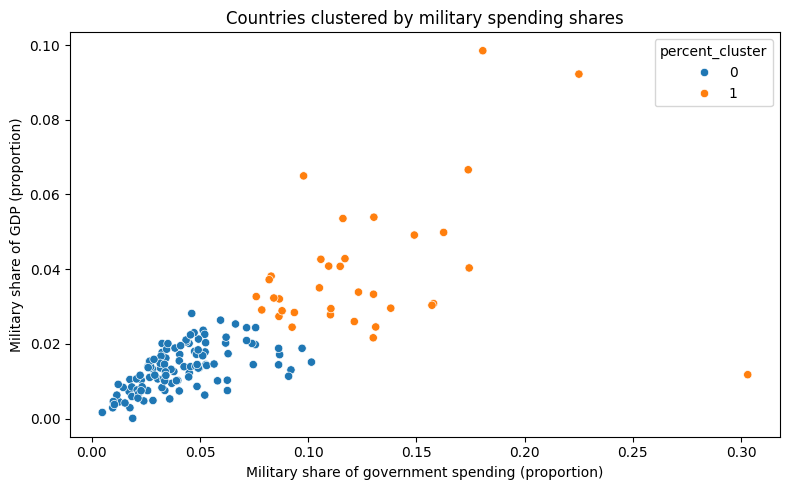

percent_cluster                              0        1
Percent of Government Spending count  113.0000  35.0000
                               mean     0.0414   0.1265
                               std      0.0207   0.0462
                               min      0.0049   0.0760
                               25%      0.0268   0.0931
                               50%      0.0385   0.1161
                               75%      0.0515   0.1436
                               max      0.1015   0.3030
Percent of GDP                 count  113.0000  35.0000
                               mean     0.0135   0.0394
                               std      0.0060   0.0182
                               min      0.0001   0.0117
                               25%      0.0091   0.0290
                               50%      0.0136   0.0333
                               75%      0.0178   0.0427
                               max      0.0281   0.0985

,Country,percent_cluster,Percent of Government Spending,Percent of GDP
5540,United States of America,1,0.081976,0.037179


Spending clusters versus percentage clusters:


percent_cluster,0,1
spending_cluster,,
0,86,25
1,26,4
2,0,1
3,1,5


In [22]:
# Q2.3: repeat with the two spending-share variables.
p2_X_percent = MinMaxScaler().fit_transform(
    p2_df[p2_percent_cols]
)
p2_percent_wcss = p2_scree(
    p2_X_percent, "Military spending shares"
)

p2_df["percent_cluster"] = p2_fit(p2_X_percent, 2).labels_

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=p2_df,
    x=p2_percent_cols[0],
    y=p2_percent_cols[1],
    hue="percent_cluster",
    palette="tab10"
)
plt.xlabel("Military share of government spending (proportion)")
plt.ylabel("Military share of GDP (proportion)")
plt.title("Countries clustered by military spending shares")
plt.tight_layout()
plt.show()

display(
    p2_df.groupby("percent_cluster")[p2_percent_cols]
    .describe().T.round(4)
)
display(
    p2_df.loc[
        p2_df["Country"] == "United States of America",
        ["Country", "percent_cluster"] + p2_percent_cols
    ]
)
print("Spending clusters versus percentage clusters:")
display(pd.crosstab(
    p2_df["spending_cluster"], p2_df["percent_cluster"]
))

### Q2.3: Results and comparison

The scree plot supports k = 2 as a reasonable broad grouping: WCSS drops from about 6.961 to 2.927 between one and two clusters, then decreases more gradually.

Cluster 0 contains 113 countries. Its average military share of government spending is about 4.14%, and its average military share of GDP is about 1.35%. Cluster 1 contains 35 countries, with corresponding averages of about 12.65% and 3.94%.

The United States belongs to cluster 1, with about 8.20% of government spending and 3.72% of GDP devoted to military expenditure. It is no longer alone because these variables measure spending relative to the government's budget and the economy, rather than the country's total expenditure.

Compared with Q2.2, the grouping now emphasizes military budget and economic shares. The cross-tabulation shows that countries from the same spending cluster can fall into different percentage clusters. Cluster labels from separate fits should not be treated as matching categories.

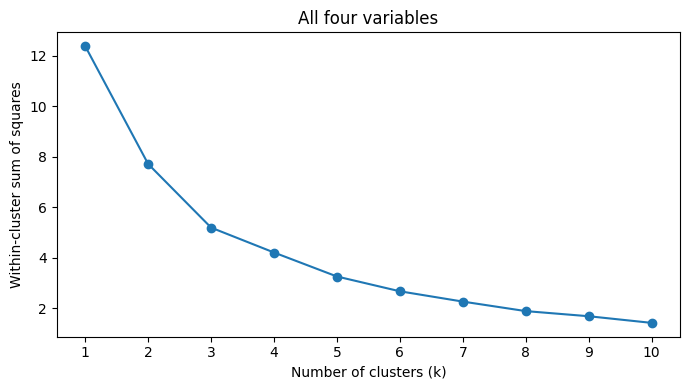

,Country count
all_cluster,
0,111
1,6
2,31


,Spending (2020 USD),Spending per Capita,Percent of Government Spending,Percent of GDP
all_cluster,,,,
0,7086.4728,196.9268,0.0404,0.0134
1,147964.5820,1875.1508,0.1354,0.0626
2,8786.0866,212.6891,0.1230,0.0335


Spending clusters versus all-variable clusters:


all_cluster,0,1,2
spending_cluster,,,
0,85,0,26
1,25,0,5
2,0,1,0
3,1,5,0


Percentage clusters versus all-variable clusters:


all_cluster,0,1,2
percent_cluster,,,
0,111,0,2
1,0,6,29


,Country,spending_cluster,percent_cluster,all_cluster
5540,United States of America,2,1,1


Countries in the U.S. all-variable cluster:


,Country
2582,Israel
2922,Kuwait
4044,Oman
4486,Saudi Arabia
4656,Singapore
5540,United States of America


In [23]:
# Q2.4: min-max normalize all four original variables.
p2_X_all = MinMaxScaler().fit_transform(p2_df[p2_variables])
p2_all_wcss = p2_scree(p2_X_all, "All four variables")

p2_df["all_cluster"] = p2_fit(p2_X_all, 3).labels_

display(p2_df.groupby("all_cluster").size().rename("Country count"))
display(
    p2_df.groupby("all_cluster")[p2_variables].mean().round(4)
)

print("Spending clusters versus all-variable clusters:")
display(pd.crosstab(
    p2_df["spending_cluster"], p2_df["all_cluster"]
))
print("Percentage clusters versus all-variable clusters:")
display(pd.crosstab(
    p2_df["percent_cluster"], p2_df["all_cluster"]
))

display(
    p2_df.loc[
        p2_df["Country"] == "United States of America",
        ["Country", "spending_cluster", "percent_cluster", "all_cluster"]
    ]
)

p2_us_all_cluster = p2_df.loc[
    p2_df["Country"] == "United States of America", "all_cluster"
].iloc[0]

print("Countries in the U.S. all-variable cluster:")
display(
    p2_df.loc[p2_df["all_cluster"] == p2_us_all_cluster, ["Country"]]
)

### Q2.4: Results and comparison

A reasonable choice is k = 3. WCSS falls from approximately 12.372 at k = 1 to 7.710 at k = 2 and 5.193 at k = 3, then to 4.207 at k = 4. The smaller improvement after three supports this choice, although the elbow is not perfectly sharp.

Cluster 0 contains 111 countries with relatively low average military spending shares. Cluster 1 contains six countries with high average spending per person and high average military spending shares: Israel, Kuwait, Oman, Saudi Arabia, Singapore, and the United States. Cluster 2 contains 31 countries with relatively high spending shares but much lower average spending per person than cluster 1.

Compared with Q2.2, the United States is no longer a singleton. Compared with Q2.3, the four-variable solution largely separates higher-share countries into two groups using spending levels as additional information. Exact membership also changes, as shown by the cross-tabulations.

### Q2.5: Useful patterns

K-means helps distinguish total military spending, spending per person, and the share of a country's budget or economy devoted to the military. The United States is exceptional in total expenditure, but it shares characteristics with other countries when spending shares and per-capita expenditure are considered together.

These groups summarize patterns in the included 2020 data; they do not establish why countries spend different amounts or measure military effectiveness. The conclusions depend on the selected countries, variables, scaling, and k. Correlated variables may also give related aspects of spending extra influence.

In [24]:
# Check the inputs and computed outputs.
for noise, data in p2_datasets.items():
    assert len(data) == 150
    assert (data.groupby("group").size() == 50).all()
    assert not data[["x1", "x2"]].isna().any().any()
    assert np.all(np.diff(p2_q1_inertias[noise]) <= 1e-8)

assert len(p2_df) == 148
assert p2_df["Country"].is_unique
assert not p2_df[p2_variables].isna().any().any()
assert all(
    pd.api.types.is_numeric_dtype(p2_df[c])
    for c in p2_variables
)
assert np.isfinite(p2_df[p2_variables].to_numpy()).all()
assert (p2_df[p2_spending_cols] > 0).all().all()
assert p2_df["Country"].eq("United States of America").sum() == 1

p2_fits = [
    ("Spending", p2_X_spending, 4, "spending_cluster"),
    ("Percentages", p2_X_percent, 2, "percent_cluster"),
    ("All four", p2_X_all, 3, "all_cluster")
]

p2_seed_checks = []
for name, X, k, column in p2_fits:
    assert np.allclose(X.min(axis=0), 0)
    assert np.allclose(X.max(axis=0), 1)
    assert p2_df[column].nunique() == k
    assert p2_df.groupby(column).size().sum() == 148

    for seed in range(5):
        other_labels = p2_fit(X, k, seed).labels_
        p2_seed_checks.append({
            "Analysis": name,
            "Seed": seed,
            "ARI versus seed 100": adjusted_rand_score(
                p2_df[column], other_labels
            )
        })

for values in [p2_spending_wcss, p2_percent_wcss, p2_all_wcss]:
    assert np.all(np.diff(values) <= 1e-8)

print("All assertions passed.")
display(pd.DataFrame(p2_seed_checks).round(4))

All assertions passed.


,Analysis,Seed,ARI versus seed 100
0,Spending,0,1.0
1,Spending,1,1.0
2,Spending,2,1.0
3,Spending,3,1.0
4,Spending,4,1.0
5,Percentages,0,1.0
6,Percentages,1,1.0
7,Percentages,2,1.0
8,Percentages,3,1.0
9,Percentages,4,1.0


### *Reflection on AI assistance
In your own words without generative AI.

AI helped me improve both questions. For Q1, I added comparisons to support showing that the elbow near three clusters becomes less clear as noise increases. In Q2, I explained the cleaning steps, proived my choices of k, and compared the groups formed from different spending variables. I also made the spending scatterplot easier to read without changing the data used by K-means.


I also had an earlier AI revision that had limitations (not shown above). It focused on Q2 and left out a complete Q1 solution. It also mentioned cluster stability without showing the check. I verified the revised work by running the cells, confirming that 148 countries remained, checking the WCSS changes, and locating the United States in each set of clusters. The seed check reproduced the same memberships, but that does not prove my choices of k are uniquely correct. Outliers and the exclusion of countries with missing data could still affect the patterns.